# Cáncer de origen primario desconocido (CUP) vs. cánceres metastásicos de primario conocido
**Versión con gráficos para el informe (figuras en `figuras_pro/`)** · **Egresos hospitalarios GRD 2019–2025 · Análisis de Datos e Inferencia Estadística**

Integrantes: Bastián Campos · Maximiliano Mella · Agustín Tapia

**Pregunta:** ¿los pacientes con CUP tienen peores resultados hospitalarios (mortalidad, estancia, severidad GRD y uso de recursos) que los pacientes con cáncer metastásico de primario conocido?

**Cómo correrlo en VS Code**
1. Abrir este archivo y elegir el kernel de Python (arriba a la derecha).
2. Los `GRD20XX.txt` (y `GRD_PUBLICO_2019.txt`, `GRD_PUBLICO_2025.txt`) deben estar en `BD/GRD_C80/` (junto a este notebook), o el comprimido en `BD/GRD_C80.rar`. En la celda 0, las líneas que imprime deben decir `True` (al menos el .rar o la carpeta). Si el notebook se abre desde otra ubicación, cambiar `CARPETA_PROYECTO`.
3. Requiere `pyarrow` para el .parquet (`pip install pyarrow`).
4. Usar **Run All** (ejecutar todo, en orden). Si ya existe la base `BD/GRD_grupos_estudio_2019_2025.parquet` tarda segundos; si no, la extracción tarda unos minutos.

## 0. Librerías y configuración

In [1]:
import io
import subprocess
import datetime as dt
import collections
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

try:
    import pyarrow  # noqa: F401  (pandas lo usa para leer y escribir .parquet)
except ImportError:
    raise ImportError('Falta pyarrow para leer la base .parquet: ejecutar  pip install pyarrow  '
                      'en la terminal y reiniciar el kernel.')

# >>> Carpeta donde está este notebook (VS Code/Jupyter la usan como directorio de trabajo).
#     Si no corresponde, poner la ruta completa, p. ej. Path(r'C:\UDD\2026_S2\Analisis Datos\Proyecto') <<<
CARPETA_PROYECTO = Path.cwd()

RUTA_RAR = CARPETA_PROYECTO / 'BD' / 'GRD_C80.rar'                     # comprimido con los GRD20XX.txt
RUTA_TXT = CARPETA_PROYECTO / 'BD' / 'GRD_C80'                         # alternativa: .txt descomprimidos
ANIOS = range(2019, 2026)              # años GRD incluidos (2019-2025)
ARCHIVO_GRUPOS = CARPETA_PROYECTO / 'BD' / f'GRD_grupos_estudio_{ANIOS[0]}_{ANIOS[-1]}.parquet'
EDAD_MINIMA = 18                       # solo adultos
REHACER_EXTRACCION = False             # True = volver a leer los .txt aunque ya exista el .parquet

print('Carpeta del proyecto:       ', CARPETA_PROYECTO)
print('Carpeta del proyecto existe:', CARPETA_PROYECTO.exists())
print('GRD_C80.rar encontrado:     ', RUTA_RAR.exists())
print('Carpeta GRD_C80 encontrada: ', RUTA_TXT.exists())
print('Base .parquet encontrada:    ', ARCHIVO_GRUPOS.exists())

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

Carpeta del proyecto:        C:\UDD\2026_S2\Analisis Datos\Proyecto
Carpeta del proyecto existe: True
GRD_C80.rar encontrado:      False
Carpeta GRD_C80 encontrada:  True
Base .parquet encontrada:     True


## 1. Grupos de estudio

| Grupo | Diagnóstico | Código CIE-10 del tumor primario |
|---|---|---|
| 1 | Cáncer de origen primario desconocido (CUP) | C80.0 |
| 2 | Cáncer de pulmón metastásico | C34 |
| 3 | Cáncer colorrectal metastásico | C18–C20 |
| 4 | Cáncer de mama metastásico | C50 |
| 5 | Cáncer de próstata metastásico | C61 |
| 6 | Cáncer gástrico metastásico | C16 |

**Reglas usadas** (los códigos se buscan en los 35 diagnósticos):
- *Metastásico* = el egreso tiene además un código de metástasis **C77, C78 o C79**.
- Los grupos 2–6 no pueden tener C80.
- Se excluyen: egresos con más de uno de los 5 primarios, egresos con C80.0 **y** alguno de los 5 primarios (contradictorio) y menores de 18 años (el análisis es solo en adultos).

**Problemas de formato de los archivos** que se corrigen al leer: cada año tiene distinta codificación (UTF-8, UTF-16, latin-1), 2023 trae fechas DD-MM-AAAA, 2024 llama `ID_BENEFICIARIO` al ID del paciente, 2022 tiene 1 fila con 130 campos, y el peso GRD usa coma decimal. 2019 y 2025 se llaman `GRD_PUBLICO_AAAA.txt`. **2025 no trae fecha de nacimiento ni comuna**: solo `TRAMO_EDAD` en tramos de 5 años, así que su edad es el punto medio del tramo (p. ej. 80–84 → 82,5) y el tramo 15–19 se excluye completo (no se puede separar a los de 18 y 19). La columna `EDAD_ORIGEN` indica de dónde salió la edad de cada egreso.

In [2]:
ENCODING = {2019: 'utf-8', 2020: 'utf-8', 2021: 'utf-8-sig', 2022: 'utf-16', 2023: 'utf-16',
            2024: 'cp1252', 2025: 'utf-8'}
PRIMARIOS = {'Pulmón': {'C34'}, 'Colorrectal': {'C18', 'C19', 'C20'}, 'Mama': {'C50'},
             'Próstata': {'C61'}, 'Gástrico': {'C16'}}
METASTASIS = {'C77', 'C78', 'C79'}
ORDEN = ['CUP', 'Pulmón', 'Colorrectal', 'Mama', 'Próstata', 'Gástrico']
FECHAS = ['FECHA_NACIMIENTO', 'FECHA_INGRESO', 'FECHAALTA', 'FECHAINTERV1', 'FECHAPROCEDIMIENTO1'] + \
         [f'FECHATRASLADO{i}' for i in range(1, 10)]


def fecha_iso(s):
    """Deja todas las fechas en AAAA-MM-DD (2023 viene en DD-MM-AAAA)."""
    s = s.strip()[:10]
    for fmt in ('%Y-%m-%d', '%d-%m-%Y'):
        try:
            return dt.datetime.strptime(s, fmt).date().isoformat()
        except ValueError:
            pass
    return ''


def clasificar(codigos):
    """Devuelve (grupo, motivo_exclusion) para la lista de diagnósticos de un egreso."""
    c3 = {c[:3] for c in codigos}
    primarios = [g for g, cods in PRIMARIOS.items() if c3 & cods]
    if any(c.startswith('C80.0') for c in codigos):
        return (None, 'C80.0 con primario conocido') if primarios else ('CUP', None)
    if not primarios or 'C80' in c3 or not (c3 & METASTASIS):
        return None, None
    if len(primarios) > 1:
        return None, 'más de un primario'
    return primarios[0], None


def abrir_anio(anio):
    """Abre el GRD del año desde la carpeta (GRD2020.txt o GRD_PUBLICO_2019.txt) o directo desde el .rar."""
    nombres = [f'GRD{anio}.txt', f'GRD_PUBLICO_{anio}.txt']
    for nombre in nombres:
        if (RUTA_TXT / nombre).exists():
            return open(RUTA_TXT / nombre, encoding=ENCODING[anio], errors='replace', newline=''), None
    if not RUTA_RAR.exists():
        raise FileNotFoundError(f'No se encontró {" ni ".join(nombres)} en {RUTA_TXT} ni {RUTA_RAR}. '
                                'Revisa CARPETA_PROYECTO en la celda 0.')
    p = subprocess.Popen(['tar', '-xOf', str(RUTA_RAR), f'GRD_C80/{nombres[0]}'], stdout=subprocess.PIPE)
    return io.TextIOWrapper(p.stdout, encoding=ENCODING[anio], errors='replace', newline=''), p


## 2. Extracción de los grupos
Se leen los ~6,94 millones de egresos línea por línea y solo se guardan los que pertenecen a algún grupo.

In [3]:
def edad_desde_tramo(tramo):
    """'[80 - 84 años]' -> (80, 82.5): inicio del tramo y su punto medio. 2025 no trae fecha de nacimiento."""
    numeros = re.findall(r'\d+', tramo)
    if len(numeros) < 2:
        return None, None
    desde, hasta = int(numeros[0]), int(numeros[1])
    return desde, (desde + hasta + 1) / 2


def extraer(anio, excluidos):
    f, proc = abrir_anio(anio)
    header = f.readline().rstrip('\r\n').lstrip('\ufeff').split('|')
    header = ['CIP_ENCRIPTADO' if c == 'ID_BENEFICIARIO' else c for c in header]
    if 'DIAGNOSTICO1' not in header:
        raise ValueError(f'GRD{anio}: no se pudo leer el encabezado. Revisa que el archivo exista y no esté dañado.')
    diag = [header.index(f'DIAGNOSTICO{i}') for i in range(1, 36)]
    fechas = [c for c in FECHAS if c in header]
    filas, total = [], 0
    for line in f:
        v = line.rstrip('\r\n').split('|')
        if len(v) != len(header):            # fila mal formada de 2022
            continue
        total += 1
        codigos = [v[j].strip().upper() for j in diag if v[j].strip()]
        grupo, motivo = clasificar(codigos)
        if motivo:
            excluidos[motivo] += 1
        if not grupo:
            continue
        fila = {k: ('' if x.strip().upper() == 'DESCONOCIDO' else x.strip()) for k, x in zip(header, v)}
        for c in fechas:
            fila[c] = fecha_iso(fila[c])
        edad, origen = None, ''
        if fila.get('FECHA_NACIMIENTO') and fila['FECHA_INGRESO']:
            edad = (dt.date.fromisoformat(fila['FECHA_INGRESO']) - dt.date.fromisoformat(fila['FECHA_NACIMIENTO'])).days / 365.25
            origen = 'fecha de nacimiento'
        elif fila.get('TRAMO_EDAD'):
            desde, edad = edad_desde_tramo(fila['TRAMO_EDAD'])
            origen = 'punto medio del tramo'
            if desde is not None and desde < EDAD_MINIMA:     # el tramo 15-19 se excluye completo
                edad = 0
        if edad is not None and edad < EDAD_MINIMA:
            excluidos[f'menor de {EDAD_MINIMA} años'] += 1
            continue
        peso = fila['IR_29301_PESO'].replace(',', '.')
        fila['IR_29301_PESO'] = '0' + peso if peso.startswith('.') else peso
        fila['ANIO'], fila['GRUPO'] = anio, grupo
        fila['EDAD'], fila['EDAD_ORIGEN'] = (round(edad, 2) if edad is not None else None), origen
        filas.append(fila)
    f.close()
    if proc:
        proc.wait()
    return header, filas, total


if 'REHACER_EXTRACCION' not in globals() or 'clasificar' not in globals():
    raise RuntimeError('Primero ejecuta las celdas anteriores (0 y 1). Lo más simple: botón "Run All".')

if REHACER_EXTRACCION or not ARCHIVO_GRUPOS.exists():
    todas, excluidos, totales, columnas = [], collections.Counter(), {}, ['ANIO', 'GRUPO', 'EDAD', 'EDAD_ORIGEN']
    for anio in ANIOS:
        cols, filas, totales[anio] = extraer(anio, excluidos)
        columnas += [c for c in cols if c not in columnas]     # 2025 trae TRAMO_EDAD y no FECHA_NACIMIENTO ni COMUNA
        todas += filas
        print(f'{anio}: {totales[anio]:,} egresos leídos -> {len(filas):,} en los grupos')
    base = pd.DataFrame(todas, columns=columnas)
    texto = base.columns.difference(['ANIO', 'EDAD'])
    base[texto] = base[texto].replace('', None)               # vacío = dato faltante (como al leer el CSV)
    base['ANIO'] = base['ANIO'].astype('int16')
    base['EDAD'] = base['EDAD'].astype(float)
    ARCHIVO_GRUPOS.parent.mkdir(parents=True, exist_ok=True)
    base.to_parquet(ARCHIVO_GRUPOS, index=False)
    print('\nTotal egresos leídos:', f'{sum(totales.values()):,}')
    print('Excluidos:', dict(excluidos))
    print('Guardado en', ARCHIVO_GRUPOS)
    del todas, base
else:
    print(f'Usando la base ya generada: {ARCHIVO_GRUPOS} (para rehacerla, poner REHACER_EXTRACCION = True)')


Usando la base ya generada: C:\UDD\2026_S2\Analisis Datos\Proyecto\BD\GRD_grupos_estudio_2019_2025.parquet (para rehacerla, poner REHACER_EXTRACCION = True)


## 3. Preparación: variables derivadas

In [4]:
df = pd.read_parquet(ARCHIVO_GRUPOS)
for c in ['FECHA_NACIMIENTO', 'FECHA_INGRESO', 'FECHAALTA']:
    df[c] = pd.to_datetime(df[c], errors='coerce')

df['ANIO'] = df['ANIO'].astype(int)
df['GRUPO'] = pd.Categorical(df['GRUPO'], ORDEN)
df['EDAD'] = df['EDAD'].astype(float)        # exacta 2019-2024; punto medio del tramo en 2025
df['DIAS_ESTADA'] = (df['FECHAALTA'] - df['FECHA_INGRESO']).dt.days
df['PESO_GRD'] = pd.to_numeric(df['IR_29301_PESO'], errors='coerce')
df['SEVERIDAD'] = pd.to_numeric(df['IR_29301_SEVERIDAD'], errors='coerce')
df['FALLECIDO'] = (df['TIPOALTA'] == 'FALLECIDO').astype(int)
df['SEV3'] = (df['SEVERIDAD'] == 3).astype(int)
df['URGENCIA'] = (df['TIPO_INGRESO'] == 'URGENCIA').astype(int)
df['MUJER'] = (df['SEXO'] == 'MUJER').astype(int)
df['USO_PABELLON'] = (pd.to_numeric(df['USOSPABELLON'], errors='coerce').fillna(0) > 0).astype(int)
df['N_PROCEDIMIENTOS'] = df[[f'PROCEDIMIENTO{i}' for i in range(1, 31)]].notna().sum(axis=1)

print(f'{len(df):,} egresos | {df.CIP_ENCRIPTADO.nunique():,} pacientes')
df[['ANIO', 'GRUPO', 'SEXO', 'EDAD', 'DIAS_ESTADA', 'TIPO_INGRESO', 'TIPOALTA', 'SEVERIDAD', 'PESO_GRD']].head()

60,816 egresos | 41,305 pacientes


,ANIO,GRUPO,SEXO,EDAD,DIAS_ESTADA,TIPO_INGRESO,TIPOALTA,SEVERIDAD,PESO_GRD
0,2019,Gástrico,HOMBRE,64.75,25,URGENCIA,DOMICILIO,2.0,0.7994
1,2019,Colorrectal,HOMBRE,82.17,14,URGENCIA,DOMICILIO,2.0,0.7000
2,2019,Colorrectal,MUJER,63.85,1,PROGRAMADA,DOMICILIO,2.0,0.9168
3,2019,Próstata,HOMBRE,70.48,2,URGENCIA,DERIVACIÓN OTRO HOSPITAL DEL SERVICIO,2.0,0.7700
4,2019,Pulmón,MUJER,60.47,7,URGENCIA,FALLECIDO,3.0,1.3157


## 4. Descripción de los datos
### 4.1 Egresos por grupo y año

In [5]:
tabla_n = pd.crosstab(df['GRUPO'], df['ANIO'], margins=True, margins_name='Total')
tabla_n['Pacientes'] = df.groupby('GRUPO', observed=True)['CIP_ENCRIPTADO'].nunique().reindex(tabla_n.index)
tabla_n.loc['Total', 'Pacientes'] = df['CIP_ENCRIPTADO'].nunique()
tabla_n

ANIO,2019,2020,2021,2022,2023,2024,2025,Total,Pacientes
GRUPO,,,,,,,,,
CUP,622,473,479,508,559,597,651,3889,3520.0
Pulmón,1378,968,868,1030,1376,1407,1679,8706,6768.0
Colorrectal,3235,2259,2329,2517,2973,3436,3832,20581,11968.0
Mama,2511,1219,1202,1478,1899,1996,2215,12520,8285.0
Próstata,954,647,708,767,1017,1210,1381,6684,4995.0
Gástrico,1201,1062,1092,1127,1218,1274,1462,8436,6124.0
Total,9901,6628,6678,7427,9042,9920,11220,60816,41305.0


**Lectura de la tabla:** 2020 y 2021 tienen menos egresos que 2019 en todos los grupos: es el efecto de la pandemia de COVID-19, que postergó hospitalizaciones (sobre todo las programadas; mama cae de 2.511 a 1.219). Desde 2022 los egresos se recuperan y en 2025 superan a 2019 en todos los grupos salvo mama. Por eso los cambios en el tiempo se miden desde 2019, el último año antes de la pandemia.

La columna *Pacientes* es aproximada: el ID cifrado cambia entre 2020 y 2021 (ningún paciente coincide entre esos dos años), así que quien se hospitalizó a ambos lados de ese corte se cuenta dos veces.

### 4.2 Datos faltantes en variables clave

In [6]:
clave = ['SEXO', 'EDAD', 'PREVISION', 'SERVICIO_SALUD', 'TIPO_INGRESO', 'FECHA_INGRESO',
         'FECHAALTA', 'TIPOALTA', 'IR_29301_COD_GRD', 'IR_29301_PESO', 'IR_29301_SEVERIDAD', 'HOSPPROCEDENCIA']
faltantes = pd.DataFrame({'n faltantes': df[clave].isna().sum(), '% faltante': (df[clave].isna().mean() * 100).round(2)})
faltantes

,n faltantes,% faltante
SEXO,5,0.01
EDAD,0,0.00
PREVISION,0,0.00
SERVICIO_SALUD,1,0.00
TIPO_INGRESO,1,0.00
FECHA_INGRESO,0,0.00
FECHAALTA,0,0.00
TIPOALTA,0,0.00
IR_29301_COD_GRD,1,0.00
IR_29301_PESO,1,0.00


Las variables clave están prácticamente completas. `HOSPPROCEDENCIA` está vacía en la mayoría de los egresos porque solo se llena cuando el paciente viene derivado de otro hospital; no es un error.

### 4.3 Valores atípicos en la estancia (regla 1,5 × RIC)

In [7]:
def atipicos(s):
    q1, q3 = s.quantile([.25, .75])
    lim = q3 + 1.5 * (q3 - q1)
    return pd.Series({'límite superior (días)': lim, 'n atípicos': (s > lim).sum(),
                      '% atípicos': round((s > lim).mean() * 100, 1), 'máximo': s.max()})

df.groupby('GRUPO', observed=True)['DIAS_ESTADA'].apply(atipicos).unstack()

,límite superior (días),n atípicos,% atípicos,máximo
GRUPO,,,,
CUP,38.0,186.0,4.8,371.0
Pulmón,30.5,525.0,6.0,118.0
Colorrectal,19.5,1970.0,9.6,369.0
Mama,16.0,1146.0,9.2,422.0
Próstata,29.5,410.0,6.1,447.0
Gástrico,27.0,580.0,6.9,248.0


Las estancias largas son clínicamente posibles (complicaciones, cuidados paliativos), así que **se mantienen** en el análisis. Por la fuerte asimetría se reportan **medianas y RIC** en vez de promedios.

## 5. Comparación de resultados hospitalarios

In [8]:
def med_ric(s):
    q1, m, q3 = s.quantile([.25, .5, .75])
    return f'{m:.0f} [{q1:.0f}–{q3:.0f}]'

resumen = df.groupby('GRUPO', observed=True).agg(
    Egresos=('FALLECIDO', 'size'),
    Edad_mediana=('EDAD', 'median'),
    Mujeres_pct=('MUJER', 'mean'),
    Urgencia_pct=('URGENCIA', 'mean'),
    Mortalidad_pct=('FALLECIDO', 'mean'),
    Severidad3_pct=('SEV3', 'mean'),
    Pabellon_pct=('USO_PABELLON', 'mean'),
    Peso_GRD_media=('PESO_GRD', 'mean'),
)
for c in ['Mujeres_pct', 'Urgencia_pct', 'Mortalidad_pct', 'Severidad3_pct', 'Pabellon_pct']:
    resumen[c] = (resumen[c] * 100).round(1)
resumen['Edad_mediana'] = resumen['Edad_mediana'].round(0)
resumen['Peso_GRD_media'] = resumen['Peso_GRD_media'].round(2)
resumen.insert(5, 'Estancia_mediana_RIC', df.groupby('GRUPO', observed=True)['DIAS_ESTADA'].apply(med_ric))
resumen

,Egresos,Edad_mediana,Mujeres_pct,Urgencia_pct,Mortalidad_pct,Estancia_mediana_RIC,Severidad3_pct,Pabellon_pct,Peso_GRD_media
GRUPO,,,,,,,,,
CUP,3889,69.0,53.8,80.9,21.7,9 [3–17],50.8,27.7,1.39
Pulmón,8706,68.0,44.4,74.6,22.1,7 [3–14],51.2,22.8,1.34
Colorrectal,20581,65.0,48.5,49.1,7.7,4 [2–9],27.6,33.2,1.49
Mama,12520,59.0,99.3,45.6,9.1,3 [1–7],24.9,36.2,1.14
Próstata,6684,73.0,0.2,78.4,13.9,6 [2–13],45.4,23.1,1.21
Gástrico,8436,66.0,32.5,58.4,12.2,5 [2–12],35.8,31.9,1.38


In [9]:
# ---------- Estilo de los gráficos (kit de la skill "graficos-profesionales") ----------
from matplotlib.patches import FancyBboxPatch

CARPETA_FIG = CARPETA_PROYECTO / 'figuras_pro'          # PNG listos para el informe y la presentación
CARPETA_FIG.mkdir(exist_ok=True)

plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.7,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 11.5, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left', 'axes.titlecolor': '#0b0b0b',
    'font.size': 10.5, 'figure.dpi': 110, 'font.family': 'sans-serif',
    'font.sans-serif': ['Segoe UI', 'DejaVu Sans'],        # solo pesos "semibold" y "normal"
    'text.parse_math': False,
})

# Colores por significado, iguales en todo el documento (paleta validada para daltonismo sobre #fcfcfb)
naranjo = '#eb6834'        # lo desfavorable: el paciente muere
violeta = '#4a3aa7'        # el grupo en estudio: CUP
gris_marca = '#b5b3ab'     # contexto: los otros cinco cánceres
tinta, gris_texto, gris_suave = '#0b0b0b', '#52514e', '#898781'
fondo_icono = '#e8e7e1'    # cuadrados "no fallece" de las matrices
COLOR_CUP = violeta


def color_grupo(g):
    return COLOR_CUP if g == 'CUP' else gris_marca


FUENTE = (f'Fuente: egresos GRD FONASA {ANIOS[0]}–{ANIOS[-1]}, pacientes de {EDAD_MINIMA} años o más '
          f'(n = {len(df):,} hospitalizaciones).'.replace(f'{len(df):,}', f'{len(df):,}'.replace(',', '.')))


def poner_titulo(figura, titulo, subtitulo, ajustar=True):
    """Título (la conclusión) y subtítulo (cómo leer el gráfico) arriba a la izquierda; fuente al pie."""
    alto = figura.get_size_inches()[1]
    espacio = (0.62 + 0.2 * (subtitulo.count('\n') + 1)) / alto
    pie = 0.32 / alto
    figura.text(0.01, 1 - 0.1 / alto, titulo, fontsize=15, fontweight='semibold', color=tinta, ha='left', va='top')
    figura.text(0.01, 1 - 0.46 / alto, subtitulo, fontsize=10.5, color=gris_texto, ha='left', va='top', linespacing=1.4)
    figura.text(0.01, 0.08 / alto, FUENTE, fontsize=8.5, color=gris_suave, ha='left', va='bottom')
    if ajustar:
        figura.tight_layout(rect=(0, pie, 1, 1 - espacio))
    else:
        figura.subplots_adjust(top=1 - espacio - 0.055)


def coma(x, decimales=1):
    return f'{x:.{decimales}f}'.replace('.', ',')


def de100(pct):
    """41.6 -> '42' (se lee 'de cada 100')."""
    return f'{pct:.0f}'


def ic_prop(x, n, z=1.96):
    """IC 95 % de Wilson para una proporción, en %."""
    x, n = np.asarray(x, float), np.asarray(n, float)
    p = x / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margen = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return (centro - margen) * 100, (centro + margen) * 100


def matriz_iconos(eje, cantidades, colores, columnas=10):
    """Matriz de 10 x 10: cantidades=[22, 78] con colores=[naranjo, fondo] dibuja '22 de cada 100'."""
    k = 0
    for cantidad, color in zip(cantidades, colores):
        for _ in range(cantidad):
            fila, columna = divmod(k, columnas)
            eje.add_patch(FancyBboxPatch((columna + 0.09, -fila + 0.09), 0.82, 0.82,
                                         boxstyle='round,pad=0,rounding_size=0.14', facecolor=color, edgecolor='none'))
            k += 1
    filas = int(np.ceil(k / columnas))
    eje.set_xlim(0, columnas)
    eje.set_ylim(-filas + 1, 1)
    eje.set_aspect('equal')
    eje.axis('off')


def rotular_finales(eje, x, finales, separacion, texto):
    """Escribe el nombre y valor al final de cada línea, separando los textos que chocarían."""
    ultimo = None
    for g, v in sorted(finales.items(), key=lambda kv: kv[1]):
        y_txt = v if ultimo is None else max(v, ultimo + separacion)
        eje.annotate(texto(g, v), xy=(x, v), xytext=(x + 0.08, y_txt), va='center', fontsize=10,
                     color=tinta, fontweight='semibold' if g == 'CUP' else 'normal')
        ultimo = y_txt


def lineas_por_grupo(eje, xs, tabla, banda=None):
    """Una línea por grupo: CUP en violeta y gruesa, los demás en gris de contexto. banda = (lo, hi) del CUP."""
    if banda is not None:
        eje.fill_between(xs, banda[0], banda[1], color=COLOR_CUP, alpha=0.14, linewidth=0)
    for g in ORDEN:
        if g not in tabla.columns:
            continue
        ys = tabla[g]
        cup = g == 'CUP'
        eje.plot(xs, ys, color=color_grupo(g), linewidth=3 if cup else 1.8, marker='o', markersize=6 if cup else 4.5,
                 zorder=3 if cup else 2)


def guardar(figura, nombre):
    figura.savefig(CARPETA_FIG / f'{nombre}.png', dpi=200)
    plt.show()

**Cómo leer los gráficos de esta sección.** Los resultados se expresan como frecuencias: "22 de cada 100 hospitalizaciones" en vez de "21,6 %". La unidad es la **hospitalización** (egreso); un mismo paciente puede tener varias. El CUP siempre va en **violeta** y los otros cinco cánceres en gris. El **margen de error** es el intervalo de confianza del 95 %: si el estudio se repitiera con otros pacientes, la cifra caería casi siempre dentro de ese rango.

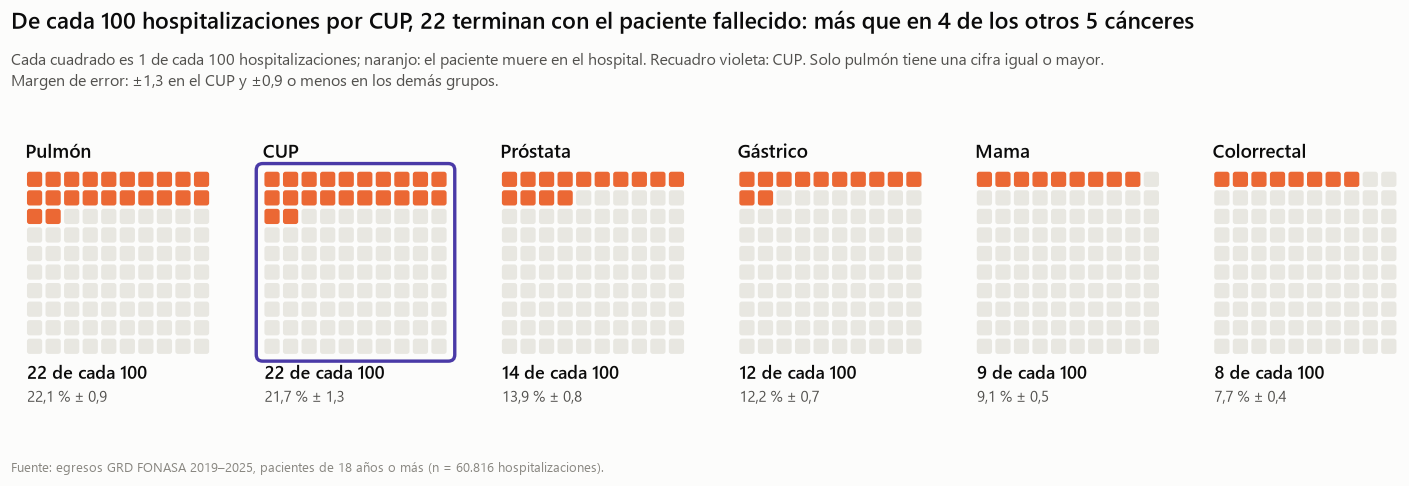

In [10]:
mort = df.groupby('GRUPO', observed=True)['FALLECIDO'].agg(['sum', 'size'])
mort['pct'] = mort['sum'] / mort['size'] * 100
lo, hi = ic_prop(mort['sum'], mort['size'])
mort['margen'] = (hi - lo) / 2
ORDEN_MORT = mort.sort_values('pct', ascending=False).index.tolist()     # mismo orden en los gráficos siguientes

cup, otros = mort.loc['CUP'], mort.drop('CUP')
n_menos = int((otros['pct'] < cup['pct']).sum())
iguales_o_mas = otros[otros['pct'] >= cup['pct']].index.tolist()

figura = plt.figure(figsize=(13, 4.4))
rejilla = figura.add_gridspec(1, 6, wspace=0.28, left=0.02, right=0.98, bottom=0.2)
poner_titulo(figura,
             f'De cada 100 hospitalizaciones por CUP, {de100(cup.pct)} terminan con el paciente fallecido: '
             f'más que en {n_menos} de los otros 5 cánceres',
             'Cada cuadrado es 1 de cada 100 hospitalizaciones; naranjo: el paciente muere en el hospital. Recuadro violeta: CUP. '
             f'Solo {" y ".join(g.lower() for g in iguales_o_mas)} tiene una cifra igual o mayor.\n'
             f'Margen de error: ±{coma(cup.margen)} en el CUP y ±{coma(otros.margen.max())} o menos en los demás grupos.',
             ajustar=False)
for k, g in enumerate(ORDEN_MORT):
    eje = figura.add_subplot(rejilla[0, k])
    n = int(round(mort.loc[g, 'pct']))
    matriz_iconos(eje, [n, 100 - n], [naranjo, fondo_icono])
    eje.set_title(g, fontsize=12.5, pad=8)
    eje.text(0.1, -9.5, f'{n} de cada 100', fontsize=12, fontweight='semibold', color=tinta, va='top')
    eje.text(0.1, -10.9, f'{coma(mort.loc[g, "pct"])} % ± {coma(mort.loc[g, "margen"])}', fontsize=9.5,
             color=gris_texto, va='top')
    if g == 'CUP':
        eje.add_patch(FancyBboxPatch((-0.35, -9.3), 10.7, 10.65, boxstyle='round,pad=0,rounding_size=0.35',
                                     fill=False, edgecolor=COLOR_CUP, linewidth=2.2, clip_on=False))
guardar(figura, '01_mortalidad_de_cada_100')

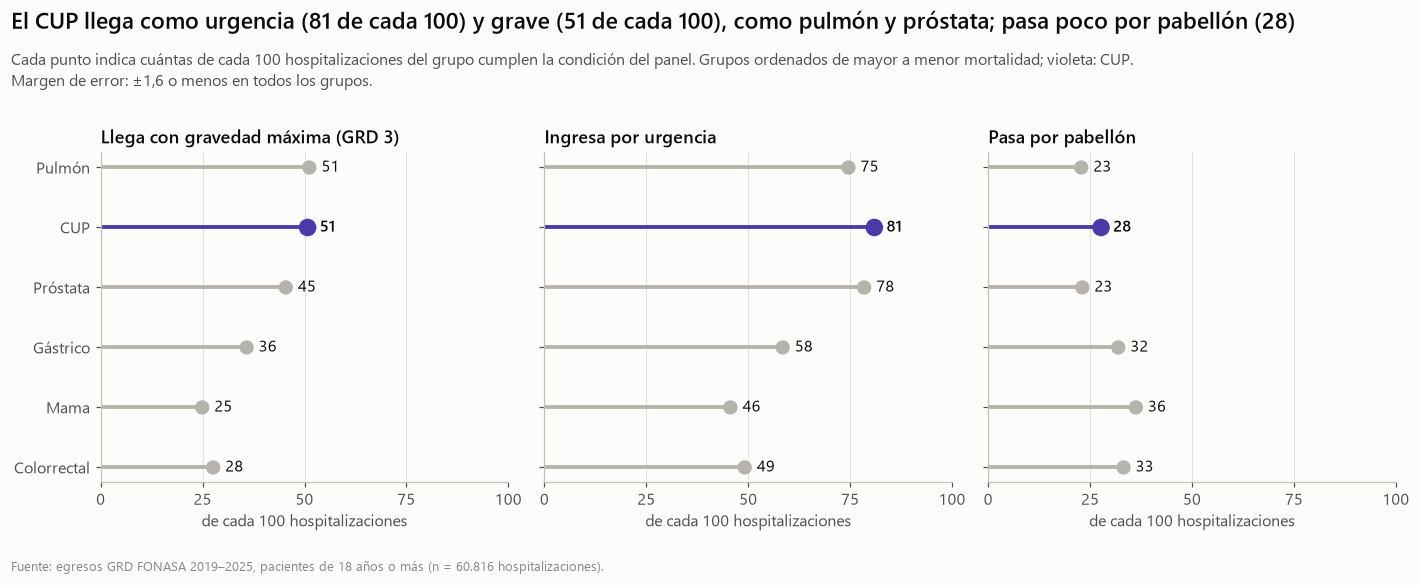

In [11]:
condiciones = [('SEV3', 'Llega con gravedad máxima (GRD 3)'), ('URGENCIA', 'Ingresa por urgencia'),
               ('USO_PABELLON', 'Pasa por pabellón')]
perfil = df.groupby('GRUPO', observed=True)[[v for v, _ in condiciones]].agg(['sum', 'size'])
pct = {v: perfil[(v, 'sum')] / perfil[(v, 'size')] * 100 for v, _ in condiciones}
margen_max = max(((ic_prop(perfil[(v, 'sum')], perfil[(v, 'size')])[1] -
                   ic_prop(perfil[(v, 'sum')], perfil[(v, 'size')])[0]) / 2).max() for v, _ in condiciones)

y = np.arange(len(ORDEN_MORT))[::-1]
figura, ejes = plt.subplots(1, 3, figsize=(13, 5.3), sharey=True)
for eje, (v, nombre) in zip(ejes, condiciones):
    valores = pct[v].loc[ORDEN_MORT]
    colores = [color_grupo(g) for g in ORDEN_MORT]
    eje.hlines(y, 0, valores, color=colores, linewidth=2.5)
    eje.scatter(valores, y, s=[110 if g == 'CUP' else 70 for g in ORDEN_MORT], color=colores, zorder=3)
    for yi, g, val in zip(y, ORDEN_MORT, valores):
        eje.text(val + 3, yi, de100(val), va='center', fontsize=10.5, color=tinta,
                 fontweight='semibold' if g == 'CUP' else 'normal')
    eje.set_xlim(0, 100)
    eje.set_xticks([0, 25, 50, 75, 100])
    eje.set_title(nombre)
    eje.set_xlabel('de cada 100 hospitalizaciones')
    eje.grid(axis='y', visible=False)
ejes[0].set_yticks(y, ORDEN_MORT)
poner_titulo(figura,
             f'El CUP llega como urgencia ({de100(pct["URGENCIA"]["CUP"])} de cada 100) y grave ({de100(pct["SEV3"]["CUP"])} de cada 100), '
             f'como pulmón y próstata; pasa poco por pabellón ({de100(pct["USO_PABELLON"]["CUP"])})',
             'Cada punto indica cuántas de cada 100 hospitalizaciones del grupo cumplen la condición del panel. '
             'Grupos ordenados de mayor a menor mortalidad; violeta: CUP.\n'
             f'Margen de error: ±{coma(margen_max)} o menos en todos los grupos.')
guardar(figura, '02_perfil_ingreso_pabellon')

**Interpretación:** 81 de cada 100 hospitalizaciones por CUP empiezan en urgencia y 51 llegan con la gravedad GRD máxima, el mismo perfil que pulmón y próstata y muy distinto del de colorrectal y mama (unas 47 urgencias y 26 graves de cada 100). Sugiere que el CUP suele diagnosticarse durante una descompensación aguda. Solo 28 de cada 100 pasan por pabellón, menos que los cánceres que se tratan con cirugía (mama 36, colorrectal 33, gástrico 32).

**Cómo leer el gráfico de estadía.** El **punto** es la estadía mediana: la mitad de las hospitalizaciones dura menos y la otra mitad, más. La **barra** cubre la mitad central (del percentil 25 al 75): deja fuera al cuarto de estadías más cortas y al cuarto de las más largas. Se usa la mediana y no el promedio porque unas pocas estadías muy largas (hasta 447 días) inflarían el promedio.

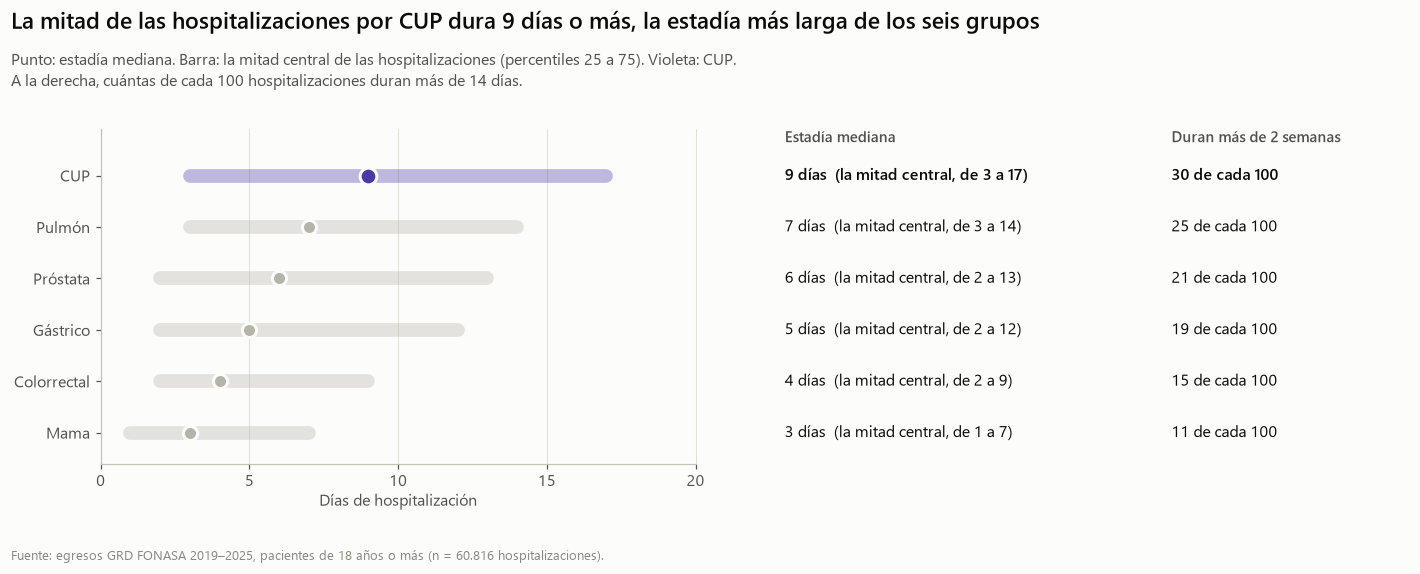

In [12]:
estadia = df.groupby('GRUPO', observed=True)['DIAS_ESTADA'].agg(
    p25=lambda s: s.quantile(.25), mediana='median', p75=lambda s: s.quantile(.75),
    mas_2_semanas=lambda s: (s > 14).mean() * 100)
filas_e = estadia.sort_values(['mediana', 'p75'], ascending=False).index.tolist()
cup_e = estadia.loc['CUP']
es_mayor = cup_e['mediana'] == estadia['mediana'].max()

y = np.arange(len(filas_e))[::-1]
figura, eje = plt.subplots(figsize=(13, 5.2))
for yi, g in zip(y, filas_e):
    r = estadia.loc[g]
    eje.hlines(yi, r.p25, r.p75, color=color_grupo(g), linewidth=9, alpha=0.35, capstyle='round')
    eje.scatter(r.mediana, yi, s=120 if g == 'CUP' else 85, color=color_grupo(g), edgecolor='#fcfcfb', linewidth=2, zorder=3)
    peso = 'semibold' if g == 'CUP' else 'normal'
    eje.text(23, yi, f'{r.mediana:.0f} días  (la mitad central, de {r.p25:.0f} a {r.p75:.0f})', va='center',
             fontsize=10.5, color=tinta, fontweight=peso)
    eje.text(36, yi, f'{de100(r.mas_2_semanas)} de cada 100', va='center', fontsize=10.5, color=tinta, fontweight=peso)
eje.text(23, len(filas_e) - 0.35, 'Estadía mediana', fontsize=10, color=gris_texto, fontweight='semibold')
eje.text(36, len(filas_e) - 0.35, 'Duran más de 2 semanas', fontsize=10, color=gris_texto, fontweight='semibold')
eje.set_xlim(0, 44)
eje.set_ylim(-0.6, len(filas_e) - 0.1)
eje.set_xticks([0, 5, 10, 15, 20])
eje.spines['bottom'].set_bounds(0, 20)
eje.set_xlabel('Días de hospitalización')
eje.xaxis.set_label_coords(10 / 44, -0.09)
eje.set_yticks(y, filas_e)
eje.grid(axis='y', visible=False)
poner_titulo(figura,
             f'La mitad de las hospitalizaciones por CUP dura {cup_e.mediana:.0f} días o más'
             + (', la estadía más larga de los seis grupos' if es_mayor else ''),
             'Punto: estadía mediana. Barra: la mitad central de las hospitalizaciones (percentiles 25 a 75). '
             'Violeta: CUP.\nA la derecha, cuántas de cada 100 hospitalizaciones duran más de 14 días.')
guardar(figura, '03_estadia')

**Interpretación:** la mitad de las hospitalizaciones por CUP dura **9 días o más** (la mitad central, de 3 a 17 días), la estadía más larga de los seis grupos; en mama la mediana es de 3 días. Además, **30 de cada 100** hospitalizaciones por CUP duran más de dos semanas (11 de cada 100 en mama). Como el CUP pasa poco por pabellón, esos días se explicarían por la búsqueda del tumor primario y el manejo de complicaciones, no por cirugías.

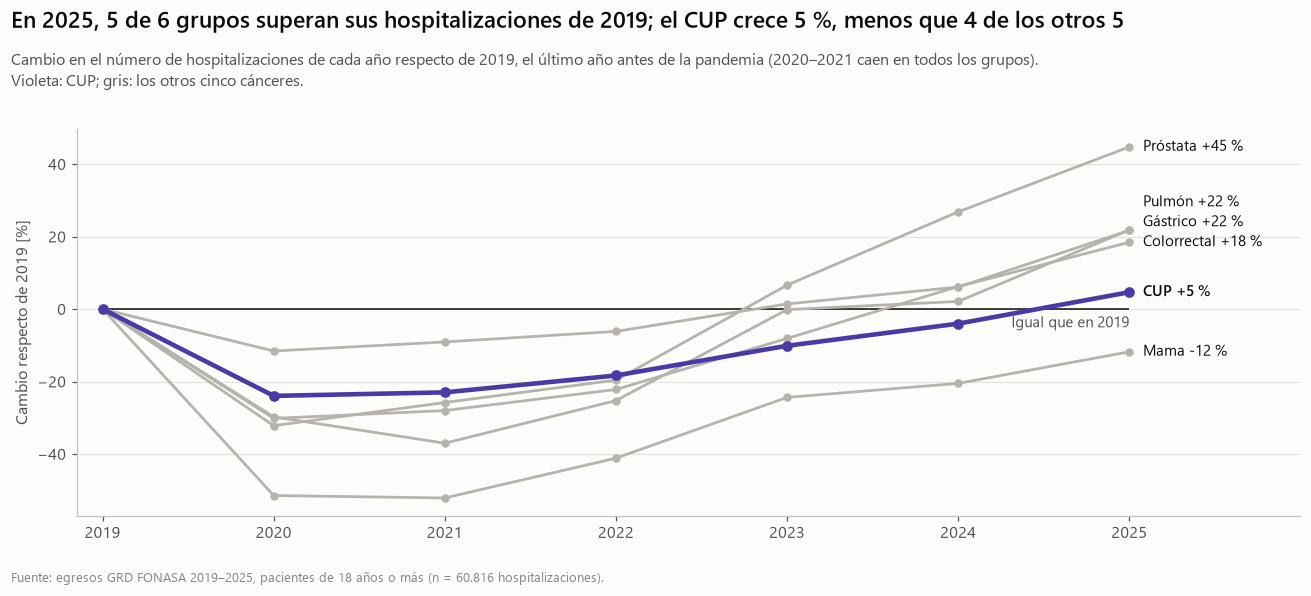

In [13]:
anual = df.groupby(['ANIO', 'GRUPO'], observed=True).agg(egresos=('FALLECIDO', 'size'),
                                                         muertes=('FALLECIDO', 'sum')).reset_index()
anual['cambio'] = (anual.egresos / anual.groupby('GRUPO', observed=True).egresos.transform('first') - 1) * 100
cambio = anual.pivot(index='ANIO', columns='GRUPO', values='cambio')
final = cambio.loc[ANIOS[-1]]
crecen_todos = bool((final > 0).all())
k_mas = int((final.drop('CUP') > final['CUP']).sum())

figura, eje = plt.subplots(figsize=(12, 5.4))
eje.hlines(0, ANIOS[0], ANIOS[-1], color=tinta, linewidth=1)
eje.text(ANIOS[-1], -2, f'Igual que en {ANIOS[0]}', fontsize=9.5, color=gris_texto, ha='right', va='top')
lineas_por_grupo(eje, cambio.index, cambio)
rotular_finales(eje, ANIOS[-1], final.to_dict(), 5.5, lambda g, v: f'{g} {"+" if v >= 0 else ""}{v:.0f} %')
eje.set_xticks(list(ANIOS))
eje.set_xlim(ANIOS[0] - .15, ANIOS[-1] + 1)
eje.set_ylabel(f'Cambio respecto de {ANIOS[0]} [%]')
eje.grid(axis='x', visible=False)
poner_titulo(figura,
             (f'Las hospitalizaciones crecen en los seis grupos entre {ANIOS[0]} y {ANIOS[-1]}' if crecen_todos
              else f'En {ANIOS[-1]}, {int((final > 0).sum())} de 6 grupos superan sus hospitalizaciones de {ANIOS[0]}')
             + f'; el CUP crece {final["CUP"]:.0f} %, menos que {k_mas} de los otros 5',
             f'Cambio en el número de hospitalizaciones de cada año respecto de {ANIOS[0]}, el último año antes de la pandemia '
             '(2020–2021 caen en todos los grupos).\nVioleta: CUP; gris: los otros cinco cánceres.')
guardar(figura, '04_crecimiento_hospitalizaciones')

**Interpretación:** en 2020 y 2021 las hospitalizaciones caen en todos los grupos por la pandemia de COVID-19 (mama, que depende más de cirugías programadas, cae a la mitad). Desde 2022 se recuperan: en 2025 próstata (+45 %), pulmón y gástrico (+22 %) y colorrectal (+18 %) ya superan con holgura a 2019, el CUP apenas lo supera (+5 %) y mama sigue un 12 % por debajo.

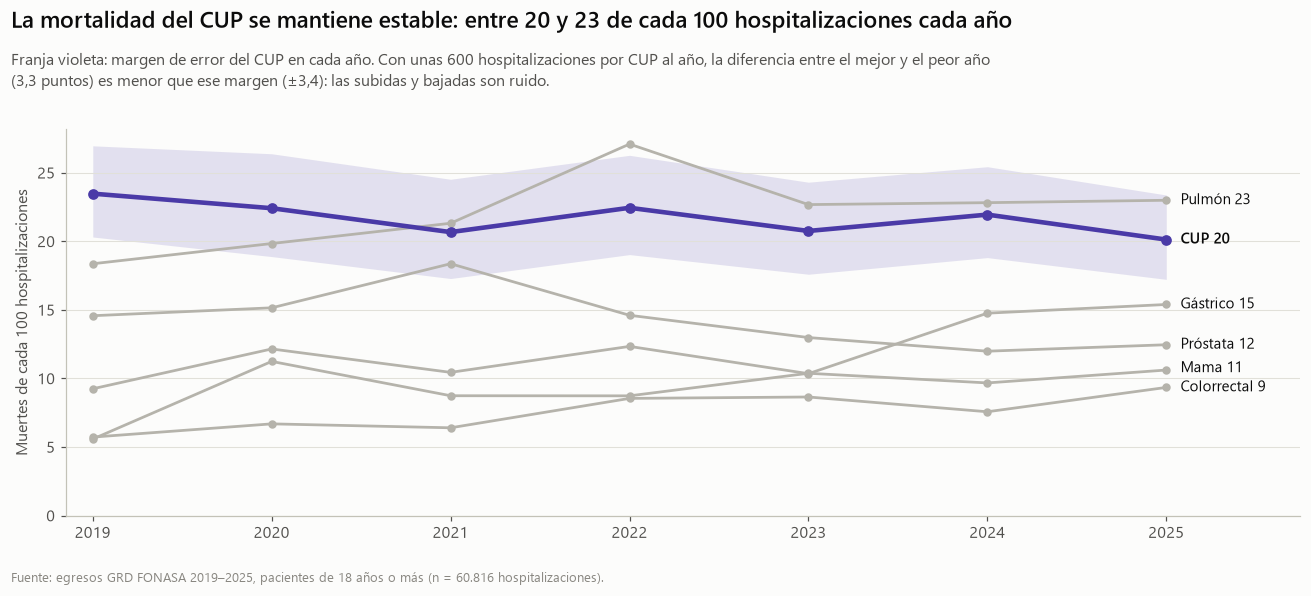

In [14]:
anual['mortalidad'] = anual.muertes / anual.egresos * 100
mort_anual = anual.pivot(index='ANIO', columns='GRUPO', values='mortalidad')
cup_a = anual[anual.GRUPO == 'CUP']
lo_a, hi_a = ic_prop(cup_a.muertes, cup_a.egresos)
rango_cup = mort_anual['CUP'].max() - mort_anual['CUP'].min()
margen_anual = ((hi_a - lo_a) / 2).mean()

figura, eje = plt.subplots(figsize=(12, 5.4))
lineas_por_grupo(eje, mort_anual.index, mort_anual, banda=(lo_a, hi_a))
rotular_finales(eje, ANIOS[-1], mort_anual.loc[ANIOS[-1]].to_dict(), 1.4, lambda g, v: f'{g} {de100(v)}')
eje.set_xticks(list(ANIOS))
eje.set_xlim(ANIOS[0] - .15, ANIOS[-1] + .75)
eje.set_ylim(0, None)
eje.set_ylabel('Muertes de cada 100 hospitalizaciones')
eje.grid(axis='x', visible=False)
poner_titulo(figura,
             f'La mortalidad del CUP se mantiene estable: entre {de100(mort_anual["CUP"].min())} y '
             f'{de100(mort_anual["CUP"].max())} de cada 100 hospitalizaciones cada año',
             f'Franja violeta: margen de error del CUP en cada año. Con unas {int(round(cup_a.egresos.mean(), -2))} hospitalizaciones '
             f'por CUP al año, la diferencia entre el mejor y el peor año\n({coma(rango_cup)} puntos) es menor que ese margen '
             f'(±{coma(margen_anual)}): las subidas y bajadas son ruido.')
guardar(figura, '05_mortalidad_por_anio')

**Interpretación:** la mortalidad del CUP se mantiene entre 20 y 23 de cada 100 todos los años y siempre en el nivel más alto junto con pulmón; desde 2023 pulmón queda levemente por encima. Las variaciones del CUP entre años son menores que su margen de error, así que no hay tendencia. El salto de pulmón en 2022 (27 de cada 100) sí es más grande que el ruido esperado, y mama duplica su mortalidad en 2020 (de 6 a 11), probablemente porque en pandemia solo se hospitalizaron los casos más graves.

### 5.1 ¿El CUP muere más solo porque llega más grave o más viejo?
Se compara la mortalidad **dentro de cada nivel de gravedad GRD** y **dentro de cada tramo de edad**. Si el CUP muriera más solo por llegar más grave o más viejo, a igual gravedad o edad su línea se juntaría con las grises. La severidad 0 (GRD sin nivel de severidad, casi sin fallecidos) se agrupa con la 1 como "baja".

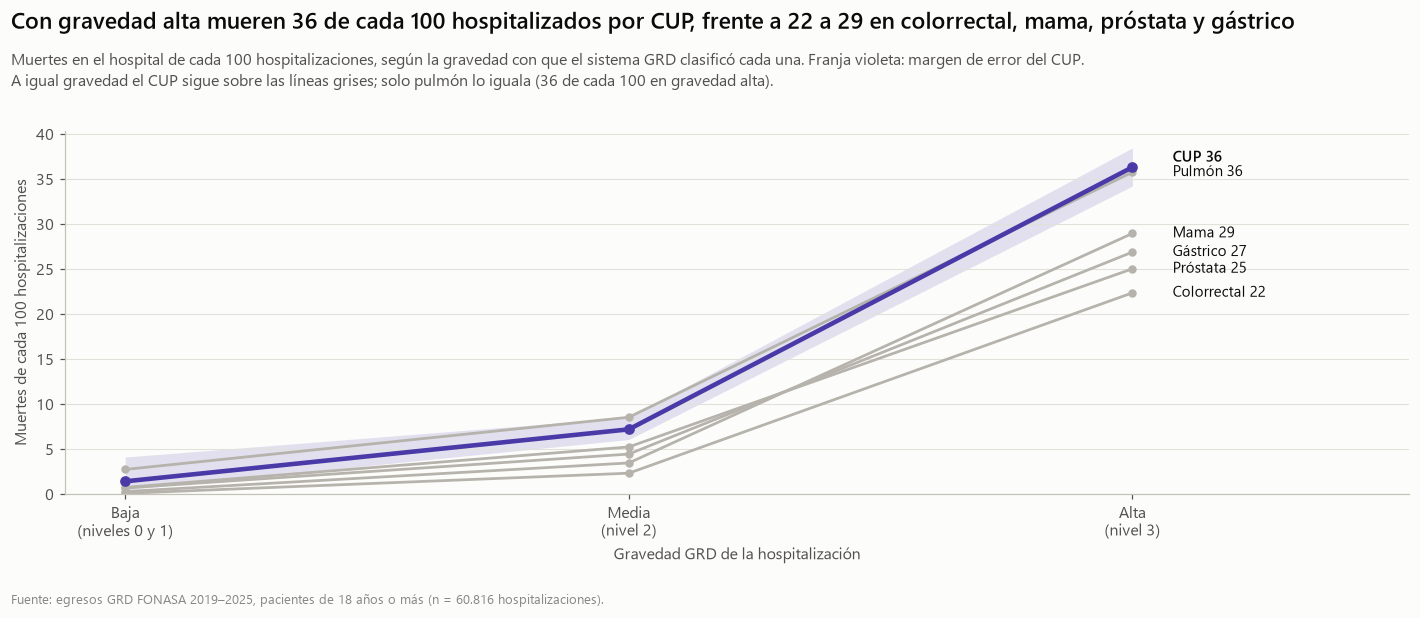

In [15]:
df['SEV_CAT'] = df['SEVERIDAD'].clip(lower=1)
NIVELES = {1: 'Baja\n(niveles 0 y 1)', 2: 'Media\n(nivel 2)', 3: 'Alta\n(nivel 3)'}
cuenta = df.groupby(['SEV_CAT', 'GRUPO'], observed=True)['FALLECIDO'].agg(['sum', 'size'])
grav = (cuenta['sum'] / cuenta['size'] * 100).unstack()
lo_g, hi_g = ic_prop(cuenta.xs('CUP', level='GRUPO')['sum'], cuenta.xs('CUP', level='GRUPO')['size'])
alta = grav.loc[3]
cuatro = alta.drop(['CUP', 'Pulmón'])

xs = np.arange(len(NIVELES))
figura, eje = plt.subplots(figsize=(13, 5.6))
lineas_por_grupo(eje, xs, grav.reset_index(drop=True), banda=(lo_g, hi_g))
rotular_finales(eje, xs[-1], alta.to_dict(), 1.6, lambda g, v: f'{g} {de100(v)}')
eje.set_xticks(xs, list(NIVELES.values()))
eje.set_xlim(-0.12, xs[-1] + 0.55)
eje.set_ylim(0, None)
eje.set_xlabel('Gravedad GRD de la hospitalización')
eje.set_ylabel('Muertes de cada 100 hospitalizaciones')
eje.grid(axis='x', visible=False)
poner_titulo(figura,
             f'Con gravedad alta mueren {de100(alta["CUP"])} de cada 100 hospitalizados por CUP, '
             f'frente a {de100(cuatro.min())} a {de100(cuatro.max())} en colorrectal, mama, próstata y gástrico',
             'Muertes en el hospital de cada 100 hospitalizaciones, según la gravedad con que el sistema GRD clasificó cada una. '
             'Franja violeta: margen de error del CUP.\n'
             f'A igual gravedad el CUP sigue sobre las líneas grises; solo pulmón lo iguala ({de100(alta["Pulmón"])} de cada 100 en gravedad alta).')
guardar(figura, '06_mortalidad_por_gravedad')

**Interpretación:** en todos los grupos la mortalidad sube fuertemente con la gravedad: con gravedad baja casi nadie fallece y con gravedad alta muere más de un tercio de los CUP. Pero **a igual gravedad, el CUP sigue arriba**: con gravedad alta mueren 36 de cada 100, igual que pulmón, frente a 22 a 29 en los otros cuatro cánceres. Que el CUP llegue más grave explica parte de su mortalidad, pero no toda.

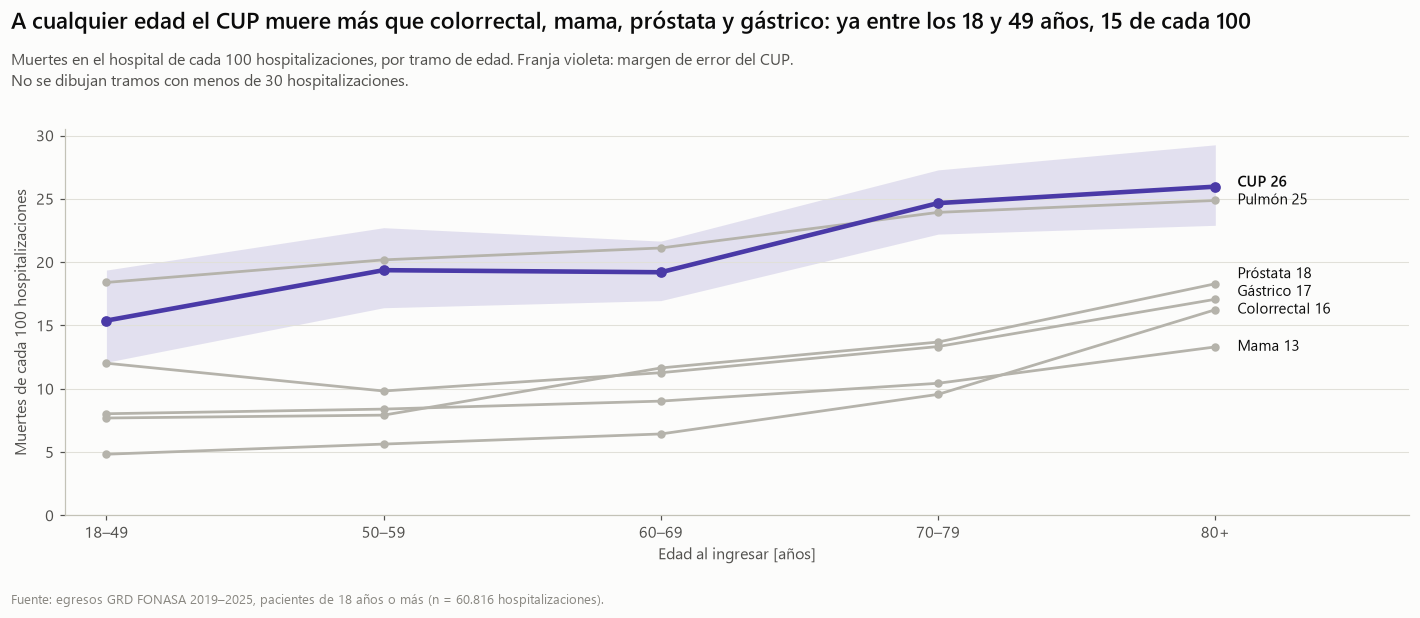

In [16]:
TRAMOS = ['18–49', '50–59', '60–69', '70–79', '80+']
df['TRAMO_EDAD'] = pd.cut(df['EDAD'], [18, 50, 60, 70, 80, 200], right=False, labels=TRAMOS)
N_MIN = 30                                   # tramos con menos hospitalizaciones no se dibujan (muy inestables)
cuenta = df.groupby(['TRAMO_EDAD', 'GRUPO'], observed=True)['FALLECIDO'].agg(['sum', 'size'])
por_edad = (cuenta['sum'] / cuenta['size'] * 100).where(cuenta['size'] >= N_MIN).unstack()
omitidos = [f'{g.lower()} de {t}' for (t, g), n in cuenta['size'].items() if n < N_MIN]
lo_e, hi_e = ic_prop(cuenta.xs('CUP', level='GRUPO')['sum'], cuenta.xs('CUP', level='GRUPO')['size'])
cuatro = por_edad.drop(columns=['CUP', 'Pulmón'])
cup_sobre_cuatro = bool((por_edad['CUP'] > cuatro.max(axis=1)).all())

xs = np.arange(len(TRAMOS))
figura, eje = plt.subplots(figsize=(13, 5.6))
lineas_por_grupo(eje, xs, por_edad.reset_index(drop=True), banda=(lo_e, hi_e))
rotular_finales(eje, xs[-1], por_edad.iloc[-1].to_dict(), 1.4, lambda g, v: f'{g} {de100(v)}')
eje.set_xticks(xs, TRAMOS)
eje.set_xlim(-0.15, xs[-1] + 0.7)
eje.set_ylim(0, None)
eje.set_xlabel('Edad al ingresar [años]')
eje.set_ylabel('Muertes de cada 100 hospitalizaciones')
eje.grid(axis='x', visible=False)
poner_titulo(figura,
             (f'A cualquier edad el CUP muere más que colorrectal, mama, próstata y gástrico: ya entre los 18 y 49 años, '
              f'{de100(por_edad["CUP"].iloc[0])} de cada 100' if cup_sobre_cuatro else
              f'Entre los 18 y 49 años mueren {de100(por_edad["CUP"].iloc[0])} de cada 100 hospitalizados por CUP'),
             'Muertes en el hospital de cada 100 hospitalizaciones, por tramo de edad. Franja violeta: margen de error del CUP.\n'
             f'No se dibujan tramos con menos de {N_MIN} hospitalizaciones' + (f' ({", ".join(omitidos)}).' if omitidos else '.'))
guardar(figura, '07_mortalidad_por_edad')

**Interpretación:** la mortalidad aumenta con la edad en todos los grupos, pero las líneas del CUP y de pulmón van **siempre por encima** de las demás: incluso entre los 18 y 49 años mueren 15 de cada 100 hospitalizados por CUP, frente a 5 a 12 en colorrectal, mama, próstata y gástrico. La diferencia de edad entre grupos (mama más joven, próstata más vieja) no explica la mayor mortalidad del CUP. La regresión de la sección 7 controla edad, sexo, gravedad y tipo de ingreso **a la vez**.

## 6. Pruebas estadísticas
### 6.1 Diferencias entre los 6 grupos

In [17]:
filas = []
for v, nombre in [('FALLECIDO', 'Mortalidad'), ('SEV3', 'Severidad 3'), ('URGENCIA', 'Ingreso urgencia'),
                  ('USO_PABELLON', 'Uso de pabellón')]:
    chi2, p, gl = stats.chi2_contingency(pd.crosstab(df['GRUPO'], df[v]))[:3]
    filas.append([nombre, 'Chi-cuadrado', round(chi2, 1), gl, p])
for v, nombre in [('DIAS_ESTADA', 'Estancia'), ('PESO_GRD', 'Peso GRD'), ('EDAD', 'Edad')]:
    h, p = stats.kruskal(*[d[v].dropna() for _, d in df.groupby('GRUPO', observed=True)])
    filas.append([nombre, 'Kruskal-Wallis', round(h, 1), 5, p])
pd.DataFrame(filas, columns=['Variable', 'Prueba', 'Estadístico', 'gl', 'p'])

,Variable,Prueba,Estadístico,gl,p
0,Mortalidad,Chi-cuadrado,1654.9,5,0.000000e+00
1,Severidad 3,Chi-cuadrado,2807.1,5,0.000000e+00
2,Ingreso urgencia,Chi-cuadrado,4428.6,5,0.000000e+00
3,Uso de pabellón,Chi-cuadrado,699.2,5,7.374457e-149
4,Estancia,Kruskal-Wallis,3431.9,5,0.000000e+00
5,Peso GRD,Kruskal-Wallis,2006.1,5,0.000000e+00
6,Edad,Kruskal-Wallis,6340.2,5,0.000000e+00


Todas las variables difieren significativamente entre los grupos (p < 0,001). Para saber **dónde** está la diferencia se compara el CUP contra cada grupo.

### 6.2 CUP vs. cada grupo (corrección de Bonferroni, 5 comparaciones)

In [18]:
cup = df[df.GRUPO == 'CUP']
filas = []
for g in ORDEN[1:]:
    otro = df[df.GRUPO == g]
    fila = {'Grupo': g}
    for v, nombre in [('FALLECIDO', 'Mortalidad'), ('SEV3', 'Severidad 3'), ('URGENCIA', 'Urgencia')]:
        par = pd.concat([cup, otro])
        p = stats.chi2_contingency(pd.crosstab(par['GRUPO'].astype(str), par[v]))[1]
        fila[f'{nombre}: dif. (pp)'] = round((cup[v].mean() - otro[v].mean()) * 100, 1)
        fila[f'{nombre}: p'] = min(p * 5, 1)
    p = stats.mannwhitneyu(cup['DIAS_ESTADA'], otro['DIAS_ESTADA'])[1]
    fila['Estancia: mediana CUP vs grupo'] = f"{cup['DIAS_ESTADA'].median():.0f} vs {otro['DIAS_ESTADA'].median():.0f}"
    fila['Estancia: p'] = min(p * 5, 1)
    filas.append(fila)

comparacion = pd.DataFrame(filas).set_index('Grupo')
comparacion.style.format({c: '{:.3g}' for c in comparacion.columns if c.endswith(': p')})

,Mortalidad: dif. (pp),Mortalidad: p,Severidad 3: dif. (pp),Severidad 3: p,Urgencia: dif. (pp),Urgencia: p,Estancia: mediana CUP vs grupo,Estancia: p
Grupo,,,,,,,,
Pulmón,-0.500000,1,-0.400000,1,6.400000,4.7e-14,9 vs 7,1.08e-12
Colorrectal,14.000000,4.46e-158,23.200000,7.49e-179,31.800000,1.1e-290,9 vs 4,5.18e-163
Mama,12.600000,1.09e-97,25.900000,9.71e-203,35.300000,0,9 vs 3,0
Próstata,7.800000,2.86e-24,5.400000,5.98e-07,2.500000,0.0122,9 vs 6,5.42e-36
Gástrico,9.400000,4.62e-41,15.000000,5.99e-55,22.500000,1.26e-130,9 vs 5,2.25e-74


**Interpretación** (p ajustado < 0,05 = diferencia significativa; *dif.* = CUP menos el otro grupo, en puntos porcentuales):
- Frente a **colorrectal, mama, gástrico y próstata**, el CUP tiene **mayor mortalidad**, más severidad y estancia más larga, todo significativo.
- Frente a **pulmón**, la mortalidad y la severidad **no difieren**: el CUP se comporta como uno de los cánceres metastásicos de peor pronóstico.

## 7. Mortalidad ajustada (regresión logística)
Los grupos tienen distinta composición (mama es casi solo mujeres, próstata solo hombres, distintas edades). La regresión compara la mortalidad **a igual edad, sexo, severidad y tipo de ingreso**. La severidad 0 (GRD sin nivel de severidad, 4.658 egresos y solo 2 fallecidos) se agrupa con la severidad 1 como "baja"; si quedara sola, la estimación es inestable (casi separación perfecta). En 2025 la edad es el punto medio del tramo de 5 años, lo que agrega un error de ±2,5 años en ese año. Se usa el CUP como referencia: un OR < 1 significa que ese grupo tiene **menos** probabilidad de morir en el hospital que el CUP.

> Requiere `statsmodels`. Si no está instalado: `pip install statsmodels` en la terminal y volver a correr la celda.

In [19]:
try:
    import statsmodels.formula.api as smf
    m = df.dropna(subset=['EDAD', 'SEVERIDAD']).copy()
    m['GRUPO'] = pd.Categorical(m['GRUPO'].astype(str), ORDEN)
    m['SEV_CAT'] = m['SEVERIDAD'].clip(lower=1).astype(int)   # 0 (sin severidad) se une a 1 = baja
    modelo = smf.logit('FALLECIDO ~ C(GRUPO) + EDAD + MUJER + C(SEV_CAT) + URGENCIA', data=m).fit(disp=0)
    ic = modelo.conf_int()
    ors = pd.DataFrame({'OR': np.exp(modelo.params), 'IC95% inf': np.exp(ic[0]), 'IC95% sup': np.exp(ic[1]),
                        'p': modelo.pvalues}).round(3)
    display(ors.drop(index='Intercept'))
except ImportError:
    print('statsmodels no está instalado: ejecutar  pip install statsmodels  y volver a correr esta celda.')

,OR,IC95% inf,IC95% sup,p
C(GRUPO)[T.Pulmón],1.124,1.017,1.242,0.022
C(GRUPO)[T.Colorrectal],0.549,0.497,0.607,0.000
C(GRUPO)[T.Mama],0.785,0.702,0.879,0.000
C(GRUPO)[T.Próstata],0.560,0.498,0.629,0.000
C(GRUPO)[T.Gástrico],0.761,0.681,0.849,0.000
C(SEV_CAT)[T.2],3.705,2.647,5.187,0.000
C(SEV_CAT)[T.3],21.811,15.604,30.487,0.000
EDAD,1.008,1.006,1.011,0.000
MUJER,0.978,0.917,1.043,0.495
URGENCIA,5.635,5.078,6.253,0.000


**Cómo leer la mortalidad ajustada.** Los OR de la tabla anterior son exactos pero difíciles de leer. Por eso el gráfico los traduce a muertes de cada 100: con el modelo se calcula cuántos morirían si **todos** los pacientes del estudio, con sus mismas edades, sexos, gravedades y tipos de ingreso, tuvieran cada diagnóstico (estandarización por el modelo). Así las diferencias que quedan ya no se deben a esas cuatro variables. El margen de error se obtiene por *bootstrap*: se repite el cálculo en 200 muestras al azar de los mismos datos.

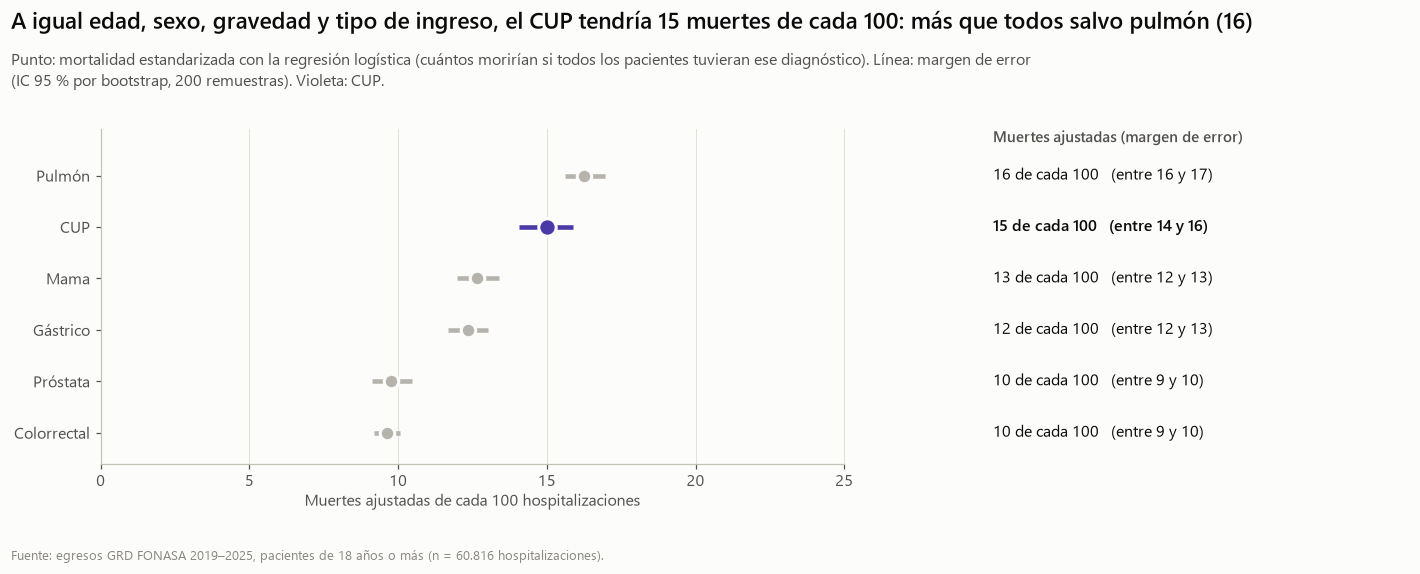

In [20]:
if 'modelo' in globals():
    FORMULA = 'FALLECIDO ~ C(GRUPO) + EDAD + MUJER + C(SEV_CAT) + URGENCIA'

    def mortalidad_ajustada(datos, ajuste):
        """Muertes de cada 100 si todos los pacientes de `datos` tuvieran cada diagnóstico."""
        return pd.Series({g: ajuste.predict(datos.assign(GRUPO=g)).mean() * 100 for g in ORDEN})

    ajustada = mortalidad_ajustada(m, modelo)
    N_BOOT = 200
    rng = np.random.default_rng(2026)
    remuestras = []
    for _ in range(N_BOOT):
        mb = m.iloc[rng.integers(0, len(m), len(m))]
        remuestras.append(mortalidad_ajustada(mb, smf.logit(FORMULA, data=mb).fit(disp=0)))
    remuestras = pd.DataFrame(remuestras)
    lo_aj, hi_aj = remuestras.quantile(.025), remuestras.quantile(.975)

    filas_a = ajustada.sort_values(ascending=False).index.tolist()
    mayores = [g for g in filas_a if ajustada[g] > ajustada['CUP']]
    y = np.arange(len(filas_a))[::-1]
    figura, eje = plt.subplots(figsize=(13, 5.2))
    for yi, g in zip(y, filas_a):
        cup = g == 'CUP'
        eje.hlines(yi, lo_aj[g], hi_aj[g], color=color_grupo(g), linewidth=3)
        eje.scatter(ajustada[g], yi, s=130 if cup else 90, color=color_grupo(g), edgecolor='#fcfcfb', linewidth=2, zorder=3)
        eje.text(30, yi, f'{de100(ajustada[g])} de cada 100   (entre {de100(lo_aj[g])} y {de100(hi_aj[g])})', va='center',
                 fontsize=10.5, color=tinta, fontweight='semibold' if cup else 'normal')
    eje.text(30, len(filas_a) - 0.35, 'Muertes ajustadas (margen de error)', fontsize=10, color=gris_texto,
             fontweight='semibold')
    eje.set_xlim(0, 44)
    eje.set_ylim(-0.6, len(filas_a) - 0.1)
    eje.set_xticks([0, 5, 10, 15, 20, 25])
    eje.spines['bottom'].set_bounds(0, 25)
    eje.set_xlabel('Muertes ajustadas de cada 100 hospitalizaciones')
    eje.xaxis.set_label_coords(12.5 / 44, -0.09)
    eje.set_yticks(y, filas_a)
    eje.grid(axis='y', visible=False)
    poner_titulo(figura,
                 f'A igual edad, sexo, gravedad y tipo de ingreso, el CUP tendría {de100(ajustada["CUP"])} muertes de cada 100'
                 + (f': más que todos salvo {" y ".join(g.lower() for g in mayores)} '
                    f'({", ".join(de100(ajustada[g]) for g in mayores)})' if mayores else ', la cifra más alta'),
                 'Punto: mortalidad estandarizada con la regresión logística (cuántos morirían si todos los pacientes tuvieran ese diagnóstico). '
                 f'Línea: margen de error\n(IC 95 % por bootstrap, {N_BOOT} remuestras). Violeta: CUP.')
    guardar(figura, '08_mortalidad_ajustada')
else:
    print('Primero ejecuta la celda de la regresión (requiere statsmodels).')

**Interpretación:** con las cuatro variables igualadas, el CUP tendría unas **15 muertes de cada 100** hospitalizaciones, frente a 13 en mama, 12 en gástrico y 10 en próstata y colorrectal; sus márgenes de error no se tocan con el del CUP, así que las diferencias son reales. Solo pulmón queda por encima (16), en línea con su OR de 1,12. Es decir, el exceso de mortalidad del CUP **no se explica** por la edad, el sexo, la gravedad ni el tipo de ingreso de sus pacientes.

Las cifras son menores que las de la primera figura (22 en el CUP) porque se calculan sobre el perfil de **todos** los pacientes del estudio, que en promedio llegan menos graves y menos por urgencia que los del CUP. El número por sí solo no se compara con la mortalidad observada; lo que importa es la comparación entre grupos: a igual perfil, el CUP muere 1,5 veces más que colorrectal o próstata.

## 8. Conclusiones preliminares
1. El CUP (C80.0) presenta una **mortalidad hospitalaria de ≈22 %**, comparable a la del cáncer de pulmón metastásico y entre 8 y 14 puntos mayor que la de los cánceres colorrectal, mama, gástrico y próstata metastásicos.
2. Los pacientes con CUP **ingresan mayoritariamente por urgencia** y con **alta severidad GRD**, lo que sugiere un diagnóstico en etapas avanzadas o en descompensación.
3. El CUP tiene la **estancia hospitalaria más larga** y un uso de pabellón menor que los cánceres quirúrgicos: consume recursos principalmente en días de cama.
4. La mayor mortalidad del CUP **no se explica solo por llegar más grave o más viejo**: se mantiene dentro de cada nivel de severidad GRD y de cada tramo de edad, y en la regresión logística ajustada por edad, sexo, severidad y tipo de ingreso los cánceres colorrectal, mama, próstata y gástrico tienen entre 21 % y 45 % menos chances de morir en el hospital que el CUP (OR 0,55–0,79). Solo pulmón queda por encima (OR 1,12).
5. **Limitaciones:** solo se conoce la mortalidad intrahospitalaria; la unidad es el egreso (un paciente puede tener varios); los diagnósticos 2–35 pueden ser antecedentes; la definición de *metastásico* depende de que la metástasis esté codificada; solo incluye hospitales públicos con GRD; en 2025 la edad es aproximada (tramos de 5 años) y se excluye el tramo 15–19; el ID cifrado del paciente no coincide entre 2020 y 2021 (0 pacientes en común), así que el conteo de pacientes únicos está sobreestimado.